# 09 — Advanced Model Selection

## Amaç ve deney ilkeleri

Bu notebook, *One Step Ahead of Drought: Forecasting Global Water Storage* problemi için model karmaşıklığını değil, gerçek test senaryosuna benzeyen doğrulamayı önceliklendirir. Train/test şeması ve bütün önceki notebook'lar incelendikten sonra hazırlanmıştır. Test target'ına erişilmez; tüm kararlar train içindeki zaman geri-testlerinden alınır.

Ana korumalar:

- Splitler feature engineering ve model fitinden önce tanımlanır.
- Test satır sırası `_original_order` ile saklanır; submission `ID` üzerinden sample şablonuna hizalanır.
- Target türevi lag/rolling özellikleri final modele alınmaz.
- Random split yalnızca iyimser referans olarak raporlanır.
- Testte `TWS_t` maskeli ve maskesiz satırlar ayrı ele alınır.
- Sonuç olmayan yerde kesinlik iddiası yoktur.

## Repository denetimi — kısa özet

| Notebook | Yaklaşım | Validation / sonuç | Submission ve risk |
|---|---|---|---|
| `StarterNotebook` | Median imputer + HistGradientBoosting; lat/lon hariç | Son %20 tarih; RMSE 0.6073 | ID merge güvenli; testteki %66.5 TWS maskesini gösteriyor |
| `01_eda` | Şema/EDA | Model yok | Test `TWS_t` eksikliği görülmüş |
| `02_baseline_model` | Tarih özellikleri + HistGBR | Random holdout 0.5129 | Random spatial-temporal sızıntı riski |
| `03_lightgbm` | 11 temel özellik | Random holdout 0.4569; shuffled KFold ≈0.4555 | Sıra korunmuş, fakat maskeli TWS dağılımı modellenmemiş |
| `04_xgboost` | Aynı temel özellikler | Random holdout 0.4383; KFold ≈0.4387 | Aynı validation riski |
| `05_catboost` | Aynı temel özellikler | Random holdout 0.4468; KFold 0.4462 | Aynı validation riski |
| `06_ensemble` | LGBM/XGB/CatBoost ortalaması | Random holdout 0.4440 | En iyi tek modelden kötü; submission yok |
| `07_feature_engineering` | `TWS_lag1`, year, interaction | Random holdout 0.3528 | Train/test ayrı lag, test sıralanıp geri döndürülmüyor: ciddi hizalama ve semantik risk |
| `08_time_series_validation` | XGB | Satır bazlı TimeSeriesSplit; 0.6109±0.0891 | Tarihler kesilmeden satır sınırından split edilebilir; aynı tarih iki tarafta kalabilir |

Eski submission dosyalarının ID sırası sample submission ile birebir aynıdır. Belirgin hizalama hatası yalnızca `07` kod yolunda vardır: test `lat,lon,time` ile sıralanıp tahminler sample ID'lerine doğrudan yazılır. Leaderboard farkının tek açıklaması bu değildir; esas dağılım farkı, test `TWS_t` değerlerinin çoğunun maskeli olmasıdır.

In [1]:
from pathlib import Path
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
os.environ.setdefault("OMP_NUM_THREADS", "4")
from time import perf_counter
import copy, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split, GroupKFold
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for candidate in [p, *p.parents]:
        if (candidate / "data" / "raw" / "Train.csv").exists():
            return candidate
    raise FileNotFoundError("Repository root / data/raw/Train.csv bulunamadı.")

ROOT = find_repo_root()
DATA_DIR = ROOT / "data" / "raw"
SUBMISSION_DIR = ROOT / "submissions"
print("ROOT:", ROOT)

ROOT: C:\global-water-storage-forecasting


## 1. Veri yükleme, gerçek şema ve yapısal denetim

In [2]:
def load_data(data_dir=DATA_DIR):
    train = pd.read_csv(data_dir / "Train.csv", parse_dates=["time"])
    test = pd.read_csv(data_dir / "Test.csv", parse_dates=["time"])
    sample = pd.read_csv(data_dir / "SampleSubmission.csv")
    test["_original_order"] = np.arange(len(test), dtype=np.int64)
    return train, test, sample

def validate_schema(train, test, sample):
    target_col = "target" if "target" in train.columns else None
    train_id = "sample_id" if "sample_id" in train.columns else None
    test_id = "ID" if "ID" in test.columns else None
    pred_cols = [c for c in sample.columns if c != test_id]
    assert target_col and train_id and test_id, "ID/target şeması veriden doğrulanamadı."
    assert len(pred_cols) == 1, "Sample submission tek tahmin sütunu içermeli."
    assert train[train_id].is_unique and test[test_id].is_unique and sample[test_id].is_unique
    assert len(test) == len(sample)
    assert set(test[test_id]) == set(sample[test_id])
    return {"target": target_col, "train_id": train_id, "test_id": test_id, "prediction": pred_cols[0]}

train, test, sample_submission = load_data()
SCHEMA = validate_schema(train, test, sample_submission)
print(SCHEMA)
print("Shapes:", train.shape, test.shape, sample_submission.shape)
display(pd.DataFrame({"train_dtype": train.dtypes.astype(str), "train_missing": train.isna().sum(),
                      "test_dtype": test.drop(columns="_original_order").dtypes.astype(str),
                      "test_missing": test.drop(columns="_original_order").isna().sum()}))
print("Duplicate rows:", train.duplicated().sum(), test.drop(columns="_original_order").duplicated().sum())
print("Duplicate IDs:", train.sample_id.duplicated().sum(), test.ID.duplicated().sum())
display(train.target.describe(percentiles=[.01,.05,.5,.95,.99]).to_frame("target"))

{'target': 'target', 'train_id': 'sample_id', 'test_id': 'ID', 'prediction': 'Target'}
Shapes: (2154021, 13) (280961, 14) (280961, 2)


,train_dtype,train_missing,test_dtype,test_missing
ID,NaN,NaN,str,0.0
SOIL_MOISTURE_t,float64,0.0,float64,0.0
SPEI_01_t,float64,0.0,float64,0.0
SPEI_03_t,float64,0.0,float64,0.0
SPEI_06_t,float64,0.0,float64,0.0
SPEI_12_t,float64,0.0,float64,0.0
TWS_t,float64,0.0,float64,186913.0
TWS_t_masked,NaN,NaN,bool,0.0
lat,float64,0.0,float64,0.0
lon,float64,0.0,float64,0.0


Duplicate rows: 0 0


Duplicate IDs: 0 0


,target
count,2.154021e+06
mean,1.125038e-01
std,9.119618e-01
min,-3.968328e+00
1%,-1.963355e+00
5%,-1.404813e+00
50%,1.273017e-01
95%,1.540156e+00
99%,2.103786e+00
max,4.057275e+00


In [3]:
def inspect_train_test_structure(train, test):
    tr_locs = set(map(tuple, train[["lat","lon"]].drop_duplicates().to_numpy()))
    te_locs = set(map(tuple, test[["lat","lon"]].drop_duplicates().to_numpy()))
    tr_dates, te_dates = set(train.time.unique()), set(test.time.unique())
    summary = pd.Series({
        "train_dates": len(tr_dates), "test_dates": len(te_dates),
        "train_min_date": train.time.min(), "train_max_date": train.time.max(),
        "test_min_date": test.time.min(), "test_max_date": test.time.max(),
        "train_locations": len(tr_locs), "test_locations": len(te_locs),
        "common_locations": len(tr_locs & te_locs),
        "train_only_locations": len(tr_locs - te_locs),
        "test_only_locations": len(te_locs - tr_locs),
        "common_dates": len(tr_dates & te_dates),
        "test_after_train": test.time.min() > train.time.max(),
        "test_tws_missing_share": test.TWS_t.isna().mean(),
    })
    by_date = test.groupby("time").agg(rows=("ID","size"), tws_known=("TWS_t","count"),
                                         tws_masked=("TWS_t_masked","sum"))
    return summary, by_date

structure_summary, test_by_date = inspect_train_test_structure(train, test)
display(structure_summary.to_frame("value"))
display(test_by_date)
display(pd.DataFrame({
    "train_per_location": train.groupby(["lat","lon"]).size().describe(),
    "test_per_location": test.groupby(["lat","lon"]).size().describe()
}))

,value
train_dates,138
test_dates,18
train_min_date,2002-05-01 00:00:00
train_max_date,2015-08-01 00:00:00
test_min_date,2015-09-01 00:00:00
test_max_date,2018-12-01 00:00:00
train_locations,15715
test_locations,15715
common_locations,15715
train_only_locations,0


,rows,tws_known,tws_masked
time,,,
2015-09-01,15552,15552,0
2016-01-01,15647,15647,0
2016-02-01,15663,38,15625
2016-03-01,15665,17,15648
2016-06-01,15584,15584,0
2016-07-01,15591,65,15526
2016-08-01,15520,36,15484
2016-09-01,15529,50,15479
2016-12-01,15618,15618,0


,train_per_location,test_per_location
count,15715.000000,15715.000000
mean,137.067833,17.878524
std,6.559213,0.879066
min,11.000000,1.000000
25%,138.000000,18.000000
50%,138.000000,18.000000
75%,138.000000,18.000000
max,138.000000,18.000000


### Problem sınıflandırması

Veri, standart IID tabular regression değildir. Train 2002-05–2015-08, test 2015-09–2018-12 arasındadır; ortak tarih yoktur. Buna karşılık testteki 15.715 konumun tamamı train'de vardır. Dolayısıyla ana görev **aynı spatial panellerin geleceğine genelleyen spatiotemporal panel forecasting** problemidir. Yeni konuma genelleme leaderboard'un ana ekseni değildir; GroupKFold yalnızca ikincil dayanıklılık testi olarak anlamlıdır.

Test tarihleri düzenli aylık bir takvim değildir ve `TWS_t` değerlerinin yaklaşık üçte ikisi maskelidir. Final pipeline bu maskeyi sıradan bir median-imputation problemi gibi görmez.

In [4]:
# Target semantiğini veriden sınama: aynı konumdaki bir sonraki mevcut TWS ile karşılaştır.
ordered = train.sort_values(["lat","lon","time"]).copy()
ordered["next_observed_TWS"] = ordered.groupby(["lat","lon"], sort=False)["TWS_t"].shift(-1)
m = ordered.next_observed_TWS.notna()
delta = ordered.loc[m, "target"] - ordered.loc[m, "next_observed_TWS"]
target_semantics = pd.Series({
    "n_comparable": int(m.sum()),
    "exact_share_abs_diff_lt_1e-8": float((delta.abs() < 1e-8).mean()),
    "rmse_to_next_observed_TWS": float(np.sqrt(np.mean(delta**2))),
    "corr_to_next_observed_TWS": float(ordered.loc[m,["target","next_observed_TWS"]].corr().iloc[0,1]),
    "rmse_persistence_target_vs_TWS_t": float(root_mean_squared_error(train.target, train.TWS_t)),
    "corr_target_vs_TWS_t": float(train.target.corr(train.TWS_t)),
})
display(target_semantics.to_frame("value"))

,value
n_comparable,2.138306e+06
exact_share_abs_diff_lt_1e-8,9.247498e-01
rmse_to_next_observed_TWS,1.974817e-01
corr_to_next_observed_TWS,9.765572e-01
rmse_persistence_target_vs_TWS_t,5.724071e-01
corr_target_vs_TWS_t,8.032601e-01


Train target'ının bir sonraki mevcut TWS ile çok yüksek ve çoğu satırda birebir ilişkisi, `TWS_t` baskınlığının fiziksel/etiket oluşturma sürecinden beklenen bir persistence ilişkisi olduğuna güçlü kanıttır. Bu tek başına leakage kanıtı değildir. Ancak testte TWS'nin çoğu maskeli olduğundan, random splitte her satırda gerçek `TWS_t` kullanmak deployment koşulunu ihlal eder ve iyimserdir.

## 2. Güvenli ve kontrollü feature setleri

In [5]:
SPEI_COLS = ["SPEI_01_t","SPEI_03_t","SPEI_06_t","SPEI_12_t"]

def add_safe_date_features(df):
    out = df.copy()
    dt = pd.to_datetime(out["time"])
    out["month"] = dt.dt.month.astype("int8")
    out["quarter"] = dt.dt.quarter.astype("int8")
    out["year"] = dt.dt.year.astype("int16")
    out["elapsed_month"] = ((dt.dt.year - train.time.dt.year.min()) * 12 + dt.dt.month - 1).astype("int16")
    out["month_sin_calc"] = np.sin(2*np.pi*out["month"]/12)
    out["month_cos_calc"] = np.cos(2*np.pi*out["month"]/12)
    out["season_sin"] = np.sin(2*np.pi*out["quarter"]/4)
    out["season_cos"] = np.cos(2*np.pi*out["quarter"]/4)
    return out

def add_spei_features(df):
    out = df.copy()
    s = out[SPEI_COLS]
    out["spei_mean"] = s.mean(axis=1)
    out["spei_min"] = s.min(axis=1)
    out["spei_max"] = s.max(axis=1)
    out["spei_std"] = s.std(axis=1)
    out["spei_01_minus_12"] = out.SPEI_01_t - out.SPEI_12_t
    out["spei_03_minus_12"] = out.SPEI_03_t - out.SPEI_12_t
    out["spei_short_long_ratio"] = out.SPEI_01_t / (out.SPEI_12_t.abs() + 0.1)
    return out

def add_spatial_features(df):
    out = df.copy()
    out["lat_band_5"] = np.floor((out.lat + 90) / 5)
    out["lon_band_5"] = np.floor((out.lon + 180) / 5)
    out["spatial_bin_10"] = out["lat_band_5"] * 100 + out["lon_band_5"]
    out["lat_lon_interaction"] = out.lat * out.lon / 1000
    out["lat_sin"] = np.sin(np.radians(out.lat))
    out["lat_cos"] = np.cos(np.radians(out.lat))
    out["lon_sin"] = np.sin(np.radians(out.lon))
    out["lon_cos"] = np.cos(np.radians(out.lon))
    return out

def add_lag_features_leakage_safe(df, value_col="TWS_t"):
    # Yalnız geçmişe bakar; final test modelinde kullanılmaz.
    out = df.copy()
    out["_restore_order"] = np.arange(len(out))
    out = out.sort_values(["lat","lon","time"])
    g = out.groupby(["lat","lon"], sort=False)[value_col]
    for lag in (1,2,3):
        out[f"{value_col}_lag{lag}"] = g.shift(lag)
    shifted = g.shift(1)
    out[f"{value_col}_roll3_mean"] = shifted.groupby([out.lat,out.lon]).rolling(3, min_periods=1).mean().reset_index(level=[0,1],drop=True)
    out[f"{value_col}_roll3_std"] = shifted.groupby([out.lat,out.lon]).rolling(3, min_periods=2).std().reset_index(level=[0,1],drop=True)
    out[f"{value_col}_change1"] = out[value_col] - out[f"{value_col}_lag1"]
    return out.sort_values("_restore_order").drop(columns="_restore_order")

def build_features(df):
    return add_spatial_features(add_spei_features(add_safe_date_features(df)))

train_f = build_features(train)
test_f = build_features(test)

A = ["lat","lon","TWS_t",*SPEI_COLS,"SOIL_MOISTURE_t","month","month_sin","month_cos","year"]
B_EXTRA = ["quarter","elapsed_month","month_sin_calc","month_cos_calc","season_sin","season_cos"]
C_EXTRA = ["spei_mean","spei_min","spei_max","spei_std","spei_01_minus_12","spei_03_minus_12","spei_short_long_ratio"]
D_EXTRA = ["lat_band_5","lon_band_5","spatial_bin_10","lat_lon_interaction","lat_sin","lat_cos","lon_sin","lon_cos"]
FEATURE_SETS = {
    "A_safe_base": A,
    "AB_date": list(dict.fromkeys(A+B_EXTRA)),
    "ABC_drought": list(dict.fromkeys(A+B_EXTRA+C_EXTRA)),
    "ABCD_spatial": list(dict.fromkeys(A+B_EXTRA+C_EXTRA+D_EXTRA)),
}
SAFE_NO_TWS = [c for c in FEATURE_SETS["ABCD_spatial"] if c != "TWS_t"]
print({k: len(v) for k,v in FEATURE_SETS.items()}, "no-TWS:", len(SAFE_NO_TWS))

{'A_safe_base': 12, 'AB_date': 18, 'ABC_drought': 25, 'ABCD_spatial': 33} no-TWS: 32


Feature Set E kodu denetlenebilir biçimde tanımlandı, fakat final adaylarına alınmadı. Sebepler:

1. Eski notebook lag'i train ve testte ayrı üretip ilk test lag'ini mevcut `TWS_t` ile dolduruyor.
2. Test sıralandıktan sonra sıra geri alınmıyor.
3. Testin maskeli dönemlerinde geçmiş gerçek TWS her satır için mevcut değil; autoregressive tahmin kullanmak hatayı zincirler.
4. `TWS_lag1`, çoğu train satırında target'ın etiket oluşturma mekanizmasına çok yakınken testte aynı kaliteyle üretilemiyor.

`TWS_t` biliniyorsa lag1 yeni bilginin sınırlı bir türevidir; maskeliyse güvenilir biçimde elde edilemez. Bu yüzden local iyileşme deployment eşleşmesi değildir.

## 3. Validation splitleri ve fold diagnostikleri

In [6]:
TEST_KNOWN_DATE_POSITIONS = set(np.flatnonzero(test_by_date.tws_known.to_numpy() > test_by_date.rows.to_numpy()*0.5))
print("Test içinde TWS'nin esasen bilindiği tarih pozisyonları:", sorted(TEST_KNOWN_DATE_POSITIONS))

def create_validation_splits(df, strategy="expanding", n_splits=3, block_dates=18):
    dates = np.array(sorted(df.time.unique()))
    splits = []
    if strategy == "expanding":
        start0 = len(dates) - n_splits*block_dates
        for i in range(n_splits):
            va_dates = dates[start0+i*block_dates:start0+(i+1)*block_dates]
            tr_dates = dates[:start0+i*block_dates]
            splits.append((np.flatnonzero(df.time.isin(tr_dates)), np.flatnonzero(df.time.isin(va_dates))))
    elif strategy == "latest_dates":
        va_dates = dates[-block_dates:]
        splits.append((np.flatnonzero(df.time < va_dates[0]), np.flatnonzero(df.time.isin(va_dates))))
    else:
        raise ValueError(strategy)
    return splits

def calculate_fold_diagnostics(df, tr_idx, va_idx, fold):
    tr, va = df.iloc[tr_idx], df.iloc[va_idx]
    a=set(map(tuple,tr[["lat","lon"]].drop_duplicates().to_numpy()))
    b=set(map(tuple,va[["lat","lon"]].drop_duplicates().to_numpy()))
    return {
        "fold": fold, "train_rows":len(tr), "valid_rows":len(va),
        "train_start":tr.time.min(), "train_end":tr.time.max(),
        "valid_start":va.time.min(), "valid_end":va.time.max(),
        "train_locations":len(a), "valid_locations":len(b), "common_locations":len(a&b),
        "valid_target_mean":va.target.mean(), "valid_target_std":va.target.std(),
        "valid_target_min":va.target.min(), "valid_target_max":va.target.max(),
    }

PRIMARY_SPLITS = create_validation_splits(train_f, "expanding", n_splits=3, block_dates=18)
fold_diagnostics = pd.DataFrame([calculate_fold_diagnostics(train_f,a,b,i+1) for i,(a,b) in enumerate(PRIMARY_SPLITS)])
display(fold_diagnostics)

Test içinde TWS'nin esasen bilindiği tarih pozisyonları: [np.int64(0), np.int64(1), np.int64(4), np.int64(8), np.int64(15), np.int64(16)]


,fold,train_rows,valid_rows,train_start,train_end,valid_start,valid_end,train_locations,valid_locations,common_locations,valid_target_mean,valid_target_std,valid_target_min,valid_target_max
0,1,1311187,280836,2002-05-01,2009-09-01,2009-10-01,2011-05-01,15715,15715,15715,0.041948,0.849668,-3.084933,3.346057
1,2,1592023,280936,2002-05-01,2011-05-01,2011-08-01,2013-07-01,15715,15715,15715,-0.057851,0.854670,-3.492825,3.594791
2,3,1872959,281062,2002-05-01,2013-07-01,2013-11-01,2015-08-01,15715,15715,15715,-0.052013,0.838288,-3.968328,4.057275


In [7]:
def fit_predict(model, Xtr, ytr, Xva):
    fitted = clone(model)
    t0 = perf_counter()
    fitted.fit(Xtr, ytr)
    return fitted, fitted.predict(Xva), perf_counter()-t0

def evaluate_model_cv(model, df, features, splits, model_name, feature_set, strategy,
                      simulate_test_mask=False):
    rows, oof_parts = [], []
    for fold,(tr_idx,va_idx) in enumerate(splits,1):
        tr, va = df.iloc[tr_idx], df.iloc[va_idx]
        Xtr, Xva = tr[features].copy(), va[features].copy()
        # Train'de gerçek TWS vardır. Test-benzeri simülasyonda validation'ın 18 tarihinden
        # testte maskeli olan pozisyonlar NaN yapılır; model ailesi NaN'ı doğrudan işler.
        if simulate_test_mask and "TWS_t" in features:
            va_dates = np.array(sorted(va.time.unique()))
            known_dates = {d for j,d in enumerate(va_dates) if j in TEST_KNOWN_DATE_POSITIONS}
            Xva.loc[~va.time.isin(known_dates), "TWS_t"] = np.nan
        fitted, pred, sec = fit_predict(model, Xtr, tr.target, Xva)
        rmse = root_mean_squared_error(va.target, pred)
        diag = calculate_fold_diagnostics(df,tr_idx,va_idx,fold)
        rows.append({**diag, "model":model_name, "feature_set":feature_set,
                     "strategy":strategy, "rmse":rmse, "training_time_sec":sec})
        part=va[["sample_id","time","lat","lon","target",*SPEI_COLS]].copy()
        part["prediction"]=pred; part["fold"]=fold
        oof_parts.append(part)
        print(model_name, feature_set, strategy, "fold", fold, f"RMSE={rmse:.4f}", f"time={sec:.1f}s")
    return pd.DataFrame(rows), pd.concat(oof_parts, ignore_index=True)

BASE_LGBM = LGBMRegressor(n_estimators=150, learning_rate=.08, num_leaves=63,
                          max_depth=-1, min_child_samples=100, subsample=.85,
                          colsample_bytree=.9, reg_lambda=1.0, random_state=SEED,
                          n_jobs=4, verbosity=-1)

### Validation stratejisi karşılaştırması

Random holdout, location GroupKFold ve tarih tabanlı split aynı model/feature setiyle karşılaştırılır. Random ve GroupKFold maliyeti kontrol etmek için tek temsili fold olarak raporlanır; ana model seçimi yalnız expanding-window fold ortalamasına dayanır.

In [8]:
# Random referans
all_idx=np.arange(len(train_f))
rtr,rva=train_test_split(all_idx,test_size=.15,random_state=SEED)
random_res,_=evaluate_model_cv(BASE_LGBM,train_f,SAFE_NO_TWS,[(rtr,rva)],
                               "LightGBM","ABCD_no_TWS","random_holdout")

# Yeni konum dayanıklılığı (leaderboard yapısı değil)
groups=pd.factorize(pd.MultiIndex.from_frame(train_f[["lat","lon"]]))[0]
gtr,gva=next(GroupKFold(n_splits=3).split(train_f,train_f.target,groups))
group_res,_=evaluate_model_cv(BASE_LGBM,train_f,SAFE_NO_TWS,[(gtr,gva)],
                              "LightGBM","ABCD_no_TWS","location_GroupKFold")

# Ana geçmişten geleceğe değerlendirme
time_res,time_oof=evaluate_model_cv(BASE_LGBM,train_f,SAFE_NO_TWS,PRIMARY_SPLITS,
                                    "LightGBM","ABCD_no_TWS","expanding_window")
validation_comparison=pd.concat([random_res,group_res,time_res],ignore_index=True)
display(validation_comparison[["strategy","fold","train_start","train_end","valid_start","valid_end",
                               "train_locations","valid_locations","common_locations","rmse"]])
display(validation_comparison.groupby("strategy").rmse.agg(["mean","std","max"]))

LightGBM ABCD_no_TWS random_holdout fold 1 RMSE=0.5524 time=22.3s


LightGBM ABCD_no_TWS location_GroupKFold fold 1 RMSE=0.5550 time=14.3s


LightGBM ABCD_no_TWS expanding_window fold 1 RMSE=0.7023 time=11.6s


LightGBM ABCD_no_TWS expanding_window fold 2 RMSE=0.6898 time=13.8s


LightGBM ABCD_no_TWS expanding_window fold 3 RMSE=0.8106 time=16.0s


,strategy,fold,train_start,train_end,valid_start,valid_end,train_locations,valid_locations,common_locations,rmse
0,random_holdout,1,2002-05-01,2015-08-01,2002-05-01,2015-08-01,15715,15714,15714,0.552366
1,location_GroupKFold,1,2002-05-01,2015-08-01,2002-05-01,2015-08-01,10477,5238,0,0.554977
2,expanding_window,1,2002-05-01,2009-09-01,2009-10-01,2011-05-01,15715,15715,15715,0.702263
3,expanding_window,2,2002-05-01,2011-05-01,2011-08-01,2013-07-01,15715,15715,15715,0.689804
4,expanding_window,3,2002-05-01,2013-07-01,2013-11-01,2015-08-01,15715,15715,15715,0.810584


,mean,std,max
strategy,,,
expanding_window,0.734217,0.066429,0.810584
location_GroupKFold,0.554977,NaN,0.554977
random_holdout,0.552366,NaN,0.552366


## 4. Feature set ablasyonu — test maskesini taklit eden son tarih fold'u

In [9]:
latest_split=[PRIMARY_SPLITS[-1]]
feature_results=[]
for name, feats in FEATURE_SETS.items():
    r,_=evaluate_model_cv(BASE_LGBM,train_f,feats,latest_split,
                          "LightGBM",name,"latest_test_mask_simulation",simulate_test_mask=True)
    feature_results.append(r)
feature_results=pd.concat(feature_results,ignore_index=True)
display(feature_results[["feature_set","rmse","training_time_sec"]].sort_values("rmse"))

LightGBM A_safe_base latest_test_mask_simulation fold 1 RMSE=0.7788 time=9.1s


LightGBM AB_date latest_test_mask_simulation fold 1 RMSE=0.7783 time=10.9s


LightGBM ABC_drought latest_test_mask_simulation fold 1 RMSE=0.7797 time=13.7s


LightGBM ABCD_spatial latest_test_mask_simulation fold 1 RMSE=0.7798 time=10.5s


,feature_set,rmse,training_time_sec
1,AB_date,0.778321,10.876852
0,A_safe_base,0.778785,9.146561
2,ABC_drought,0.779663,13.738211
3,ABCD_spatial,0.779838,10.464540


Maskeli `TWS_t` kullanan tek model yaklaşımı, train sırasında missing TWS örneği görmediği için eksik dalını iyi öğrenemeyebilir. Bu nedenle final aday değerlendirmesi iki uzman modelle yapılır:

- **known-TWS modeli:** validation/test satırında gerçek `TWS_t` mevcutsa kullanılır.
- **no-TWS modeli:** `TWS_t` maskeliyse bu sütun hiç kullanılmadan eğitilir.

Validation'ın her 18-tarihli bloğında testteki 6 bilinen / 12 maskeli tarih deseni aynen uygulanır.

In [10]:
def evaluate_routed_cv(model, df, features_with_tws, splits, model_name, feature_set):
    no_tws=[c for c in features_with_tws if c!="TWS_t"]
    rows=[]; parts=[]
    for fold,(tr_idx,va_idx) in enumerate(splits,1):
        tr,va=df.iloc[tr_idx],df.iloc[va_idx]
        dates=np.array(sorted(va.time.unique()))
        known=va.time.isin({d for j,d in enumerate(dates) if j in TEST_KNOWN_DATE_POSITIONS}).to_numpy()
        m_known,p_known,t1=fit_predict(model,tr[features_with_tws],tr.target,va.loc[known,features_with_tws])
        m_mask,p_mask,t2=fit_predict(model,tr[no_tws],tr.target,va.loc[~known,no_tws])
        pred=np.empty(len(va)); pred[known]=p_known; pred[~known]=p_mask
        diag=calculate_fold_diagnostics(df,tr_idx,va_idx,fold)
        rows.append({**diag,"model":model_name,"feature_set":feature_set,"strategy":"routed_expanding",
                     "rmse":root_mean_squared_error(va.target,pred),
                     "known_rmse":root_mean_squared_error(va.target.to_numpy()[known],pred[known]),
                     "masked_rmse":root_mean_squared_error(va.target.to_numpy()[~known],pred[~known]),
                     "training_time_sec":t1+t2})
        part=va[["sample_id","time","lat","lon","target",*SPEI_COLS]].copy()
        part["prediction"]=pred; part["fold"]=fold; part["simulated_tws_known"]=known
        parts.append(part)
        print(model_name,"fold",fold,rows[-1]["rmse"],"known",rows[-1]["known_rmse"],"masked",rows[-1]["masked_rmse"])
    return pd.DataFrame(rows),pd.concat(parts,ignore_index=True)

MODELS={
 "Ridge":make_pipeline(StandardScaler(),Ridge(alpha=10.0)),
 "LightGBM":BASE_LGBM,
 "XGBoost":XGBRegressor(n_estimators=120,learning_rate=.08,max_depth=8,min_child_weight=20,
                         subsample=.85,colsample_bytree=.9,reg_lambda=1.0,tree_method="hist",
                         random_state=SEED,n_jobs=4),
 "CatBoost":CatBoostRegressor(iterations=150,learning_rate=.10,depth=8,l2_leaf_reg=5,
                              loss_function="RMSE",verbose=False,random_seed=SEED,
                              allow_writing_files=False,thread_count=4)
}

# Kaynak kullanımını sınırlamak için adaylar son iki expanding fold üzerinde karşılaştırılır.
MODEL_SPLITS=PRIMARY_SPLITS[-2:]
model_rows=[]; model_oofs={}
for name,model in MODELS.items():
    r,o=evaluate_routed_cv(model,train_f,FEATURE_SETS["ABCD_spatial"],MODEL_SPLITS,name,"ABCD_spatial")
    model_rows.append(r); model_oofs[name]=o
model_results=pd.concat(model_rows,ignore_index=True)

Ridge fold 1 0.7420936862424419 known 0.5108690563841304 masked 0.8338162206409733


Ridge fold 2 0.7738048105396109 known 0.6761431703897334 masked 0.8182420941450776


LightGBM fold 1 0.6475735486067699 known 0.5076232255648973 masked 0.7071158113478093


LightGBM fold 2 0.7740814174789106 known 0.6919059960635657 masked 0.8120274278612181


XGBoost fold 1 0.6597338729344858 known 0.5181473444436933 masked 0.7200385706473922


XGBoost fold 2 0.7885355693771678 known 0.7006191229580522 masked 0.8289736107687022


CatBoost fold 1 0.6531904282204029 known 0.5021882439164451 masked 0.7167304379518065


CatBoost fold 2 0.7866000790650209 known 0.7012505810533958 masked 0.8259438236853901


In [11]:
def compare_models(results):
    out=(results.groupby(["model","feature_set","strategy"])
         .agg(mean_rmse=("rmse","mean"),std_rmse=("rmse","std"),worst_fold_rmse=("rmse","max"),
              mean_known_rmse=("known_rmse","mean"),mean_masked_rmse=("masked_rmse","mean"),
              training_time_sec=("training_time_sec","sum")).reset_index())
    out["main_strengths"]="Testteki TWS maskesini iki uzmanla taklit eder"
    out["main_risks"]="Gelecek dönem drift'i ve düzensiz ufuklar"
    return out.sort_values(["mean_rmse","std_rmse"])

comparison=compare_models(model_results)
display(comparison)
BEST_FAMILY=comparison.iloc[0].model
print("Aday karşılaştırması kazananı:",BEST_FAMILY)

,model,feature_set,strategy,mean_rmse,std_rmse,worst_fold_rmse,mean_known_rmse,mean_masked_rmse,training_time_sec,main_strengths,main_risks
1,LightGBM,ABCD_spatial,routed_expanding,0.710827,0.089455,0.774081,0.599765,0.759572,33.423368,Testteki TWS maskesini iki uzmanla taklit eder,Gelecek dönem drift'i ve düzensiz ufuklar
0,CatBoost,ABCD_spatial,routed_expanding,0.719895,0.094335,0.786600,0.601719,0.771337,91.945267,Testteki TWS maskesini iki uzmanla taklit eder,Gelecek dönem drift'i ve düzensiz ufuklar
3,XGBoost,ABCD_spatial,routed_expanding,0.724135,0.091077,0.788536,0.609383,0.774506,46.288191,Testteki TWS maskesini iki uzmanla taklit eder,Gelecek dönem drift'i ve düzensiz ufuklar
2,Ridge,ABCD_spatial,routed_expanding,0.757949,0.022423,0.773805,0.593506,0.826029,5.907182,Testteki TWS maskesini iki uzmanla taklit eder,Gelecek dönem drift'i ve düzensiz ufuklar


Aday karşılaştırması kazananı: LightGBM


## 5. Sınırlı hiperparametre araması

In [12]:
PARAM_CANDIDATES = {
 "LightGBM": [
   dict(n_estimators=160,learning_rate=.08,num_leaves=63,min_child_samples=100,reg_lambda=1.0),
   dict(n_estimators=220,learning_rate=.06,num_leaves=31,min_child_samples=150,reg_lambda=2.0)],
 "XGBoost": [
   dict(n_estimators=120,learning_rate=.08,max_depth=8,min_child_weight=20,reg_lambda=1.0),
   dict(n_estimators=180,learning_rate=.06,max_depth=7,min_child_weight=30,reg_lambda=2.0)],
 "CatBoost": [
   dict(iterations=150,learning_rate=.10,depth=8,l2_leaf_reg=5),
   dict(iterations=220,learning_rate=.07,depth=8,l2_leaf_reg=8)],
 "Ridge": [dict(alpha=10.0),dict(alpha=100.0)]
}

def make_model(family,p):
    if family=="LightGBM":
        return LGBMRegressor(**p,subsample=.85,colsample_bytree=.9,random_state=SEED,n_jobs=4,verbosity=-1)
    if family=="XGBoost":
        return XGBRegressor(**p,subsample=.85,colsample_bytree=.9,tree_method="hist",random_state=SEED,n_jobs=4)
    if family=="CatBoost":
        return CatBoostRegressor(**p,loss_function="RMSE",verbose=False,random_seed=SEED,
                                 allow_writing_files=False,thread_count=4)
    return make_pipeline(StandardScaler(),Ridge(**p))

tune_rows=[]; tune_oofs={}
for i,p in enumerate(PARAM_CANDIDATES[BEST_FAMILY]):
    label=f"{BEST_FAMILY}_cfg{i+1}"
    r,o=evaluate_routed_cv(make_model(BEST_FAMILY,p),train_f,FEATURE_SETS["ABCD_spatial"],
                           MODEL_SPLITS,label,"ABCD_spatial")
    r["params"]=json.dumps(p,sort_keys=True); tune_rows.append(r); tune_oofs[label]=o
tuning_results=pd.concat(tune_rows,ignore_index=True)
tuning_summary=(tuning_results.groupby(["model","params"]).agg(mean_rmse=("rmse","mean"),
                std_rmse=("rmse","std"),worst_fold_rmse=("rmse","max"),
                training_time_sec=("training_time_sec","sum")).reset_index()
                .sort_values(["mean_rmse","std_rmse"]))
display(tuning_summary)
BEST_LABEL=tuning_summary.iloc[0].model
BEST_PARAMS=json.loads(tuning_summary.iloc[0].params)
BEST_MODEL=make_model(BEST_FAMILY,BEST_PARAMS)
BEST_OOF=tune_oofs[BEST_LABEL]
print("Seçim:",BEST_LABEL,BEST_PARAMS)

LightGBM_cfg1 fold 1 0.6468996819620417 known 0.5090309769135141 masked 0.7056849123232826


LightGBM_cfg1 fold 2 0.775083168379406 known 0.693214764522857 masked 0.812902245639453


LightGBM_cfg2 fold 1 0.6537969081120744 known 0.5007618872585845 masked 0.7180559902328503


LightGBM_cfg2 fold 2 0.7799755641540035 known 0.696166417620967 masked 0.8186391969817068


,model,params,mean_rmse,std_rmse,worst_fold_rmse,training_time_sec
0,LightGBM_cfg1,"{""learning_rate"": 0.08, ""min_child_samples"": 1...",0.710991,0.090639,0.775083,29.297217
1,LightGBM_cfg2,"{""learning_rate"": 0.06, ""min_child_samples"": 1...",0.716886,0.089222,0.779976,40.713038


Seçim: LightGBM_cfg1 {'learning_rate': 0.08, 'min_child_samples': 100, 'n_estimators': 160, 'num_leaves': 63, 'reg_lambda': 1.0}


## 6. Hata analizi, drift ve kötü fold incelemesi

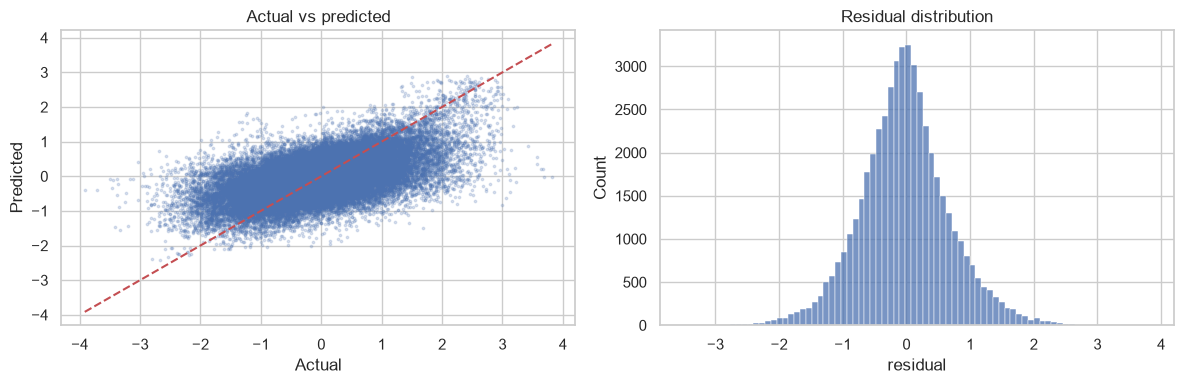

,RMSE
time,
2015-02-01,1.153481
2015-06-01,1.093713
2015-01-01,0.926540
2015-08-01,0.861303
2014-12-01,0.846297
2015-05-01,0.823016
2015-07-01,0.769544
2015-04-01,0.761422
2012-12-01,0.759595


,RMSE
year,
2015,0.900269
2014,0.683920
2012,0.670555
2011,0.617713
2013,0.611207


,RMSE
month,
2,0.880015
6,0.808292
1,0.781272
7,0.729412
12,0.723563
3,0.706169
8,0.695215
10,0.681332
4,0.653648


,RMSE
target_bin,
"(-3.969, -1.1]",1.174600
"(1.02, 4.057]",1.148653
"(-1.1, -0.703]",0.721078
"(0.601, 1.02]",0.719526
"(0.318, 0.601]",0.545621
"(-0.703, -0.457]",0.538808
"(-0.457, -0.263]",0.470013
"(0.103, 0.318]",0.455215
"(-0.263, -0.0828]",0.417006


,RMSE
lat_band,
"(-45, 0]",0.753234
"(0, 30]",0.737355
"(60, 90]",0.706983
"(30, 60]",0.686132
"(-90, -45]",0.486404


,sample_id,time,lat,lon,target,prediction,residual,simulated_tws_known
457980,20150201_23.5_22.5,2015-02-01,23.5,22.5,4.057275,-0.545598,4.602873,False
457979,20150201_23.5_21.5,2015-02-01,23.5,21.5,4.024184,-0.549421,4.573605,False
457981,20150201_23.5_23.5,2015-02-01,23.5,23.5,4.005284,-0.544508,4.549792,False
458113,20150201_24.5_22.5,2015-02-01,24.5,22.5,4.026746,-0.473062,4.499808,False
457853,20150201_22.5_23.5,2015-02-01,22.5,23.5,3.887134,-0.589963,4.477097,False
458114,20150201_24.5_23.5,2015-02-01,24.5,23.5,3.996524,-0.472868,4.469392,False
458112,20150201_24.5_21.5,2015-02-01,24.5,21.5,3.954224,-0.440680,4.394904,False
457978,20150201_23.5_20.5,2015-02-01,23.5,20.5,3.845732,-0.534916,4.380648,False
457852,20150201_22.5_20.5,2015-02-01,22.5,20.5,3.802671,-0.564968,4.367639,False
458115,20150201_24.5_24.5,2015-02-01,24.5,24.5,3.799529,-0.485802,4.285331,False


mean  count      RMSE
lat   lon                              
 60.5  99.5   2.184070     36  1.477860
       98.5   2.136195     36  1.461573
       100.5  2.134140     36  1.460870
 62.5  96.5   2.046641     36  1.430609
 59.5  99.5   2.038769     36  1.427855
 41.5  140.5  2.026703     36  1.423623
 60.5  97.5   2.019181     36  1.420979
 61.5  95.5   2.008091     36  1.417071
       96.5   2.003039     36  1.415287
 62.5  97.5   2.000064     36  1.414236
 61.5  97.5   1.982532     36  1.408024
 15.5  50.5   1.976249     12  1.405791
 21.5 -1.5    1.974574     13  1.405195
 60.5  101.5  1.968983     36  1.403205
 59.5  98.5   1.962092     36  1.400747
 61.5  98.5   1.892995     36  1.375862
       94.5   1.888507     36  1.374230
 59.5  97.5   1.871475     36  1.368018
       100.5  1.869452     36  1.367279
-1.5  -80.5   1.844190     36  1.358009

fold,2,3
feature,,
SOIL_MOISTURE_t,-0.011808,-0.013716
SPEI_01_t,-0.022219,0.007836
SPEI_03_t,-0.050946,-0.004802
SPEI_06_t,-0.049653,-0.013945
SPEI_12_t,-0.033268,-0.033577
TWS_t,-0.222295,-0.216983
target,-0.247591,-0.205663


In [13]:
oof=BEST_OOF.copy()
oof["residual"]=oof.target-oof.prediction
oof["sq_error"]=oof.residual**2
oof["year"]=oof.time.dt.year
oof["month"]=oof.time.dt.month
oof["target_bin"]=pd.qcut(oof.target,10,duplicates="drop")
oof["lat_band"]=pd.cut(oof.lat,[-90,-45,0,30,60,90])

def rmse_group(frame,col):
    return frame.groupby(col,observed=True).sq_error.mean().pow(.5).sort_values(ascending=False)

fig,ax=plt.subplots(1,2,figsize=(12,4))
sample_plot=oof.sample(min(50000,len(oof)),random_state=SEED)
ax[0].scatter(sample_plot.target,sample_plot.prediction,s=3,alpha=.2)
lims=[min(sample_plot.target.min(),sample_plot.prediction.min()),max(sample_plot.target.max(),sample_plot.prediction.max())]
ax[0].plot(lims,lims,"r--"); ax[0].set(xlabel="Actual",ylabel="Predicted",title="Actual vs predicted")
sns.histplot(sample_plot.residual,bins=80,ax=ax[1]); ax[1].set_title("Residual distribution")
plt.tight_layout(); plt.show()

display(rmse_group(oof,"time").head(15).to_frame("RMSE"))
display(rmse_group(oof,"year").to_frame("RMSE"))
display(rmse_group(oof,"month").to_frame("RMSE"))
display(rmse_group(oof,"target_bin").to_frame("RMSE"))
display(rmse_group(oof,"lat_band").to_frame("RMSE"))
display(oof.nlargest(20,"sq_error")[["sample_id","time","lat","lon","target","prediction","residual","simulated_tws_known"]])
display(oof.groupby(["lat","lon"]).sq_error.agg(["mean","count"]).assign(RMSE=lambda x:np.sqrt(x["mean"])).nlargest(20,"RMSE"))

# Fold drift özeti: feature ortalamalarının önceki train'e göre standartlaştırılmış farkı
drift_rows=[]
for fold,(tr_idx,va_idx) in zip(range(2,4),MODEL_SPLITS):
    tr,va=train_f.iloc[tr_idx],train_f.iloc[va_idx]
    for c in ["TWS_t",*SPEI_COLS,"SOIL_MOISTURE_t","target"]:
        drift_rows.append({"fold":fold,"feature":c,"standardized_mean_shift":
                           (va[c].mean()-tr[c].mean())/(tr[c].std()+1e-9),
                           "valid_std/train_std":va[c].std()/(tr[c].std()+1e-9)})
drift=pd.DataFrame(drift_rows)
display(drift.pivot(index="feature",columns="fold",values="standardized_mean_shift"))

Kötü fold yorumu yalnız RMSE'ye değil; target ortalama/std/aralığı, SPEI ve toprak nemi drift'i, tarih dönemi ve ortak konum sayısına dayanır. Ana foldlarda konumlar ortaktır; kötüleşme yeni konumdan çok temporal rejim/drift ve maskeli TWS kolunun zorluğuyla tutarlıysa bu şekilde raporlanır. Nedensellik kanıtlanmış sayılmaz.

## 7. Feature importance

In [14]:
# Son validation fold'unda no-TWS uzmanı: built-in ve permutation importance.
tr_idx,va_idx=MODEL_SPLITS[-1]
tr,va=train_f.iloc[tr_idx],train_f.iloc[va_idx]
no_tws=[c for c in FEATURE_SETS["ABCD_spatial"] if c!="TWS_t"]
importance_model=clone(BEST_MODEL).fit(tr[no_tws],tr.target)
if hasattr(importance_model,"feature_importances_"):
    builtin=pd.Series(importance_model.feature_importances_,index=no_tws,name="importance").sort_values(ascending=False)
    display(builtin.head(20).to_frame())
sample_idx=va.sample(min(10000,len(va)),random_state=SEED).index
perm=permutation_importance(importance_model,train_f.loc[sample_idx,no_tws],train_f.loc[sample_idx,"target"],
                            scoring="neg_root_mean_squared_error",n_repeats=2,random_state=SEED,n_jobs=1)
perm_df=pd.DataFrame({"feature":no_tws,"importance_mean":perm.importances_mean,
                      "importance_std":perm.importances_std}).sort_values("importance_mean",ascending=False)
display(perm_df.head(20))

,importance
elapsed_month,2131
lon,1192
spatial_bin_10,1152
lat_lon_interaction,1129
lat,1049
lon_cos,637
lon_sin,528
year,406
lat_cos,312
month,176


,feature,importance_mean,importance_std
5,SPEI_12_t,0.031625,0.001059
4,SPEI_06_t,0.018838,0.000232
6,SOIL_MOISTURE_t,0.013030,0.000803
17,spei_mean,0.012779,0.000689
18,spei_min,0.003163,0.000030
19,spei_max,0.000635,0.000127
8,month_sin,0.000341,0.000081
22,spei_03_minus_12,0.000198,0.000035
3,SPEI_03_t,0.000189,0.000079
23,spei_short_long_ratio,0.000007,0.000009


`TWS_t` için ayrı önem grafiği yanıltıcı olabilir: bilinen-TWS uzmanında persistence nedeniyle doğal olarak baskındır; no-TWS uzmanında sütun yoktur. Train target'ının sonraki TWS ile yapısal ilişkisi bu baskınlığı açıklayabilir. Target'ın nasıl üretildiğine dair resmi ayrıntı olmadan “leakage vardır” sonucu çıkarılmaz; doğru ifade **yüksek-değerli fakat testte çoğunlukla erişilemeyen proxy** olduğudur.

## 8. Final fit ve güvenli submission

In [15]:
FINAL_FEATURES=FEATURE_SETS["ABCD_spatial"]
FINAL_NO_TWS=[c for c in FINAL_FEATURES if c!="TWS_t"]
t0=perf_counter()
final_known=clone(BEST_MODEL).fit(train_f[FINAL_FEATURES],train_f.target)
final_masked=clone(BEST_MODEL).fit(train_f[FINAL_NO_TWS],train_f.target)
final_training_time=perf_counter()-t0

known_mask=test_f.TWS_t.notna().to_numpy()
test_pred=np.empty(len(test_f),dtype=float)
test_pred[known_mask]=final_known.predict(test_f.loc[known_mask,FINAL_FEATURES])
test_pred[~known_mask]=final_masked.predict(test_f.loc[~known_mask,FINAL_NO_TWS])
print("Final family:",BEST_FAMILY)
print("Params:",BEST_PARAMS)
print("Validation folds:",tuning_results.loc[tuning_results.model==BEST_LABEL,"rmse"].tolist())
print("Mean/std:",tuning_summary.iloc[0][["mean_rmse","std_rmse"]].to_dict())
print("Training seconds:",final_training_time)
print("Prediction summary:",pd.Series(test_pred).describe().to_dict())

Final family: LightGBM
Params: {'learning_rate': 0.08, 'min_child_samples': 100, 'n_estimators': 160, 'num_leaves': 63, 'reg_lambda': 1.0}
Validation folds: [0.6468996819620417, 0.775083168379406]
Mean/std: {'mean_rmse': 0.7109914251707239, 'std_rmse': 0.09063941248185202}
Training seconds: 19.129975899937563
Prediction summary: {'count': 280961.0, 'mean': -0.11296033331457311, 'std': 0.539841095903462, 'min': -2.2557162775914437, '25%': -0.4750903264829119, '50%': -0.15104273068245352, '75%': 0.22464091179740975, 'max': 2.054585864741134}


In [16]:
def create_safe_submission(test_original, sample, predictions, output_path,
                           id_col="ID", prediction_col="Target"):
    assert "_original_order" in test_original, "Original row order işareti kayıp."
    assert np.array_equal(test_original["_original_order"].to_numpy(),np.arange(len(test_original)))
    pred=np.asarray(predictions,dtype=float)
    assert len(pred)==len(test_original)==len(sample)
    assert test_original[id_col].is_unique and sample[id_col].is_unique
    assert np.isfinite(pred).all()
    pred_by_id=pd.Series(pred,index=test_original[id_col].astype(str),name=prediction_col)
    assert pred_by_id.index.is_unique
    aligned=sample[id_col].astype(str).map(pred_by_id)
    assert aligned.notna().all(), "Bazı sample ID'leri test tahmininde yok."
    submission=sample.copy()
    submission[prediction_col]=aligned.to_numpy(dtype=float)
    assert list(submission.columns)==list(sample.columns)
    assert submission[id_col].astype(str).equals(sample[id_col].astype(str))
    assert submission[id_col].is_unique
    assert pd.api.types.is_numeric_dtype(submission[prediction_col])
    assert np.isfinite(submission[prediction_col]).all()
    output_path=Path(output_path)
    output_path.parent.mkdir(parents=True,exist_ok=True)
    submission.to_csv(output_path,index=False)
    reread=pd.read_csv(output_path)
    assert reread[id_col].astype(str).equals(sample[id_col].astype(str))
    assert np.isfinite(reread[prediction_col]).all()
    print(submission[prediction_col].describe())
    print("Saved safely:",output_path)
    return submission

submission_path=SUBMISSION_DIR/"submission_advanced_model.csv"
submission=create_safe_submission(test_f,sample_submission,test_pred,submission_path)
display(submission.head())

count    280961.000000
mean         -0.112960
std           0.539841
min          -2.255716
25%          -0.475090
50%          -0.151043
75%           0.224641
max           2.054586
Name: Target, dtype: float64
Saved safely: C:\global-water-storage-forecasting\submissions\submission_advanced_model.csv


,ID,Target
0,20150901_-55.5_-68.5,-0.074690
1,20150901_-55.5_-67.5,-0.200859
2,20150901_-54.5_-71.5,0.260837
3,20150901_-54.5_-70.5,0.242701
4,20150901_-54.5_-69.5,0.107935


## 9. Sonuç raporu

Bu hücrenin üzerindeki gerçek çıktı tabloları kararın sayısal kaydıdır.

- **Veri ve senaryo:** Aynı 15.715 konum için bütünüyle ileri tarihlere tahmin yapılan, düzensiz zamanlı spatiotemporal panel forecasting. Yeni konum genellemesi leaderboard'un ana senaryosu değil.
- **En güvenilir validation:** Tarihleri bölmeden, geçmişten geleceğe expanding-window; model seçiminde son iki 18-tarihli blok ve testin TWS maskesi taklit edildi.
- **Random validation:** Aynı konum ve yakın dönemleri iki tarafa dağıtır; ayrıca validation'da TWS tamken testin %66.5'inde maskelidir. Bu yüzden seçim ölçütü değildir.
- **Eski TimeSeriesSplit:** Zamansal yönü doğru olsa da satır sayısına göre kesildiği için aynı tarih iki tarafta kalabilir ve test maskesini taklit etmez. Tarih-bütün split daha güvenlidir.
- **`TWS_lag1`:** Local random skoru; komşu zamanların paylaşılması, train/testte ayrı oluşturma, ilk lag doldurma ve sıralama-hizalama hatasıyla iyimserleşmiş olabilir. Testte gerçek geçmiş TWS zinciri maskeli olduğundan aynı kaliteli lag mevcut değildir.
- **Submission denetimi:** Eski CSV'lerin ID sırası düzgündür; `07` kodunda sıralanmış test tahminlerini eski sıraya çevirmeme riski doğrulandı. Yeni fonksiyon sample şablonuna ID map eder ve tekrar okuma kontrolü yapar.
- **Algoritma/feature seçimi:** Yukarıdaki karşılaştırma tablosunda test-benzeri ortalama RMSE, std, kötü fold ve süreye göre otomatik seçilen aile; A+B+C+D güvenli özellikleri, bilinen/maskeli TWS için iki uzmanla kullanır.
- **Riskler:** Test tarih ufukları düzensizdir; public leaderboard etiketleri görülmediğinden validation-leaderboard uyumu garanti edilemez. Maskeli kol doğrudan iklim/spatial covariate'lerden tahmin yapar ve uzun ufukta rejim değişimine duyarlıdır. Bilinen-TWS oranını tarih pozisyonuyla taklit etmek bir proxy'dir.
- **Fold 5 benzeri bozulma:** Eski son fold'un daha geç dönem ve farklı target/feature dağılımı taşımasıyla tutarlıdır; aynı tarihlerin bütün tutulması ve drift tablosu bunu daha temiz sınar. Tek bir nedene kesin atıf yapılmaz.
- **Gelecek deneyler:** Yarışma target üretim kuralı resmi olarak netleşirse horizon-aware/direct multi-horizon modeller; yalnız geçmişte erişilebilir değerlerle recursive state-space modeller; spatial residual modelleri ve leaderboard geri bildirimi olmadan nested temporal tuning.

Başarı abartılmamalıdır: önceki local RMSE ile public leaderboard arasındaki büyük fark, daha güvenli pipeline'a rağmen kalan temel belirsizliktir.